In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/Users/abzohiani/Documents/Energy Data Analytics Career Plan/df_fuel_ckan.csv")

In [2]:
df.transpose().head(df.shape[0]) # Transpose DataFrame to preview data from all columns 

,0,1,2,3,4,5,6,7,8,9,...,309921,309922,309923,309924,309925,309926,309927,309928,309929,309930
DATETIME,2009-01-01T00:00:00,2009-01-01T00:30:00,2009-01-01T01:00:00,2009-01-01T01:30:00,2009-01-01T02:00:00,2009-01-01T02:30:00,2009-01-01T03:00:00,2009-01-01T03:30:00,2009-01-01T04:00:00,2009-01-01T04:30:00,...,2026-09-05T16:30:00,2026-09-05T17:00:00,2026-09-05T17:30:00,2026-09-05T18:00:00,2026-09-05T18:30:00,2026-09-05T19:00:00,2026-09-05T19:30:00,2026-09-05T20:00:00,2026-09-05T20:30:00,2026-09-05T21:00:00
GAS,8367.0,8495.0,8471.0,8318.0,8295.0,8304.0,8358.0,8314.0,8547.0,8810.0,...,5043.0,5940.0,6627.0,7068.0,7666.0,7669.0,7604.0,7549.0,7372.0,6813.0
COAL,15037.0,15095.0,15088.0,15035.0,15005.0,15018.0,15010.0,14968.0,15050.0,15157.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
NUCLEAR,7099.0,7088.0,7074.0,7064.0,7052.0,7041.0,7030.0,7020.0,7008.0,6999.0,...,4368.0,4366.0,4368.0,4368.0,4365.0,4370.0,4367.0,4364.0,4367.0,4365.0
WIND,248.0,229.0,207.0,191.0,175.0,162.0,155.0,143.0,132.0,124.0,...,4965.0,4263.0,3536.0,2948.0,2689.0,2686.0,2618.0,2556.0,2578.0,2439.0
WIND_EMB,62.0,57.0,52.0,48.0,44.0,40.0,39.0,36.0,33.0,31.0,...,994.0,927.0,773.0,663.0,587.0,542.0,498.0,450.0,434.0,440.0
HYDRO,246.0,245.0,246.0,246.0,246.0,236.0,226.0,225.0,225.0,224.0,...,273.0,409.0,447.0,466.0,471.0,473.0,475.0,475.0,475.0,492.0
IMPORTS,2518.0,2495.0,2465.0,2439.0,2363.0,2336.0,2206.0,2171.0,1936.0,1900.0,...,7410.0,7726.0,7626.0,6824.0,6824.0,6824.0,6824.0,6824.0,6824.0,6824.0
BIOMASS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2552.0,2886.0,3089.0,3133.0,3155.0,3161.0,3165.0,3162.0,3160.0,3161.0
OTHER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,714.0,700.0,1300.0,2388.0,2381.0,2491.0,2145.0,1528.0,864.0,863.0


There are 34 columns in the original DataFrame. For purposes of this analysis, I have decided to simplify the NESO Generation Mix DataFrame by only keeping the most important columns. I will filter the DataFrame for 2025 data only before dropping columns.

In [3]:
df_2025 = df[df["DATETIME"].str.contains("2025")] 
# Filter for 2025 data only. We should only have 17520 rows in the new DataFrame

In [4]:
df_2025.shape

(17520, 34)

In [5]:
keep_columns = [
    "DATETIME",
    "CARBON_INTENSITY",
    "GAS",
    "COAL",
    "NUCLEAR",
    "WIND",
    "WIND_EMB",
    "HYDRO",
    "SOLAR",
    "BIOMASS",
    "IMPORTS",
    "STORAGE",
    "GENERATION"
]

df_gen = df_2025[keep_columns].copy()

In [6]:
df_gen.shape

(17520, 13)

In [7]:
df_gen.info()

<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 280512 to 298031
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   DATETIME          17520 non-null  str    
 1   CARBON_INTENSITY  17520 non-null  float64
 2   GAS               17520 non-null  float64
 3   COAL              17520 non-null  float64
 4   NUCLEAR           17520 non-null  float64
 5   WIND              17520 non-null  float64
 6   WIND_EMB          17520 non-null  float64
 7   HYDRO             17520 non-null  float64
 8   SOLAR             17520 non-null  float64
 9   BIOMASS           17520 non-null  float64
 10  IMPORTS           17520 non-null  float64
 11  STORAGE           17520 non-null  float64
 12  GENERATION        17520 non-null  float64
dtypes: float64(12), str(1)
memory usage: 1.7 MB


The slimmed-down DataFrame now has 13 columns as expected. 'DATETIME' has 'str' data type which needs to be converted to a Python datetime object, especially important as this generation mix DataFrame will be merged with the demand DataFrame for 2025 on the 'DATETIME' column, and both data types have to match.

In [8]:
df_gen["DATETIME"] = pd.to_datetime(df_gen["DATETIME"])
df_gen["HOUR"] = df_gen["DATETIME"].dt.hour
df_gen["DAY_OF_WEEK"] = df_gen["DATETIME"].dt.day_name()
df_gen["MONTH_NAME"] = df_gen["DATETIME"].dt.month_name()


In [9]:
df_week4_demand = pd.read_csv("/Users/abzohiani/Documents/Energy Data Analytics Career Plan/demanddata_2025.csv")

In [10]:
df_week4_demand.head()

,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,2025-01-01,1,21036,26215,19918,5405,6606,0,19270,0,...,-1518,-1026,1,-232,-386,-558,96,0,241,0
1,2025-01-01,2,21222,26063,20167,5358,6606,0,19270,0,...,-1513,-1023,1,-124,-282,-564,51,0,262,0
2,2025-01-01,3,21385,25734,20328,5237,6606,0,19270,0,...,-1428,-922,1,-119,-384,-205,62,0,414,0
3,2025-01-01,4,20473,24988,19460,5115,6606,0,19270,0,...,-1423,-915,0,-119,-334,-193,37,0,423,0
4,2025-01-01,5,19634,24912,18654,5080,6606,0,19270,0,...,-1539,-899,0,-119,-363,-622,-282,0,288,0


In [11]:
df_week4_demand.shape

(17520, 22)

In [12]:
df_week4_demand.info()

<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   SETTLEMENT_DATE            17520 non-null  str  
 1   SETTLEMENT_PERIOD          17520 non-null  int64
 2   ND                         17520 non-null  int64
 3   TSD                        17520 non-null  int64
 4   ENGLAND_WALES_DEMAND       17520 non-null  int64
 5   EMBEDDED_WIND_GENERATION   17520 non-null  int64
 6   EMBEDDED_WIND_CAPACITY     17520 non-null  int64
 7   EMBEDDED_SOLAR_GENERATION  17520 non-null  int64
 8   EMBEDDED_SOLAR_CAPACITY    17520 non-null  int64
 9   NON_BM_STOR                17520 non-null  int64
 10  PUMP_STORAGE_PUMPING       17520 non-null  int64
 11  SCOTTISH_TRANSFER          17520 non-null  int64
 12  IFA_FLOW                   17520 non-null  int64
 13  IFA2_FLOW                  17520 non-null  int64
 14  BRITNED_FLOW               17520 

In [13]:
demand_keep_columns = [
    "SETTLEMENT_DATE",
    "SETTLEMENT_PERIOD",
    "ND",
]

df_demand = df_week4_demand[demand_keep_columns].copy()

In [14]:
df_demand.shape

(17520, 3)

In [15]:
df_demand["SETTLEMENT_DATE"].head()

0    2025-01-01
1    2025-01-01
2    2025-01-01
3    2025-01-01
4    2025-01-01
Name: SETTLEMENT_DATE, dtype: str

In [16]:
df_demand["SETTLEMENT_DATE"].dtype

<StringDtype(storage='python', na_value=nan)>

This string data type 'SETTLEMENT_DATE' needs to be formatted to match the 'DATETIME' column in df_gen before merging the DataFrames on that column.

In [17]:
df_demand["SETTLEMENT_DATE"] = pd.to_datetime(df_demand["SETTLEMENT_DATE"])

In [18]:
df_demand["SETTLEMENT_DATE"].dtype

dtype('<M8[us]')

In [19]:
df_gen["DATETIME"].dtype

dtype('<M8[us]')

In [20]:
df_gen["DATETIME"].head()

280512   2025-01-01 00:00:00
280513   2025-01-01 00:30:00
280514   2025-01-01 01:00:00
280515   2025-01-01 01:30:00
280516   2025-01-01 02:00:00
Name: DATETIME, dtype: datetime64[us]

In [21]:
df_demand["DATETIME"] = (
    pd.to_datetime(df_demand["SETTLEMENT_DATE"])
    + pd.to_timedelta((df_demand["SETTLEMENT_PERIOD"] - 1) * 30, unit="min")
)

In [22]:
df_merged = pd.merge(
    df_gen,
    df_demand,
    on="DATETIME",
    how="inner"
)

In [23]:
df_merged.columns.tolist()

['DATETIME',
 'CARBON_INTENSITY',
 'GAS',
 'COAL',
 'NUCLEAR',
 'WIND',
 'WIND_EMB',
 'HYDRO',
 'SOLAR',
 'BIOMASS',
 'IMPORTS',
 'STORAGE',
 'GENERATION',
 'HOUR',
 'DAY_OF_WEEK',
 'MONTH_NAME',
 'SETTLEMENT_DATE',
 'SETTLEMENT_PERIOD',
 'ND']

In [24]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   DATETIME           17520 non-null  datetime64[us]
 1   CARBON_INTENSITY   17520 non-null  float64       
 2   GAS                17520 non-null  float64       
 3   COAL               17520 non-null  float64       
 4   NUCLEAR            17520 non-null  float64       
 5   WIND               17520 non-null  float64       
 6   WIND_EMB           17520 non-null  float64       
 7   HYDRO              17520 non-null  float64       
 8   SOLAR              17520 non-null  float64       
 9   BIOMASS            17520 non-null  float64       
 10  IMPORTS            17520 non-null  float64       
 11  STORAGE            17520 non-null  float64       
 12  GENERATION         17520 non-null  float64       
 13  HOUR               17520 non-null  int32         
 14  DAY_OF_WEEK      

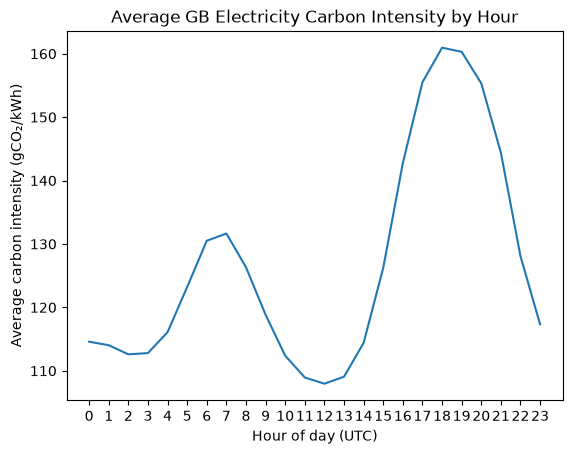

In [25]:
# Question 1a: How does carbon intensity vary by hour?

hourly_ci = df_merged.groupby("HOUR")["CARBON_INTENSITY"].mean()

# Plot carbon intensity vs hour of day

plt.plot(hourly_ci.index, hourly_ci.values)

plt.xlabel("Hour of day (UTC)")
plt.ylabel("Average carbon intensity (gCO₂/kWh)")
plt.title("Average GB Electricity Carbon Intensity by Hour")

plt.xticks(range(0, 24))

plt.show()

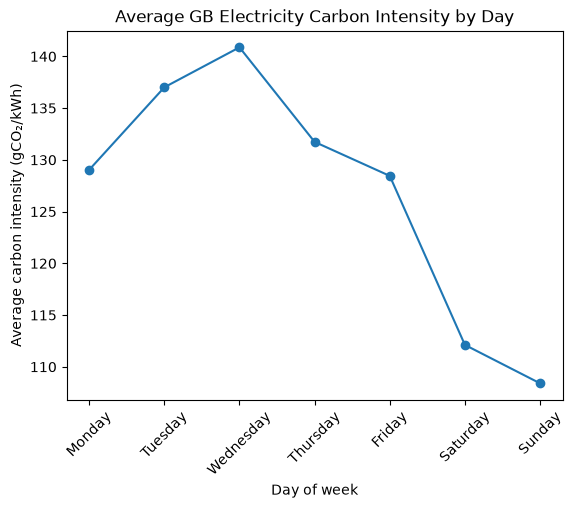

In [26]:
# Question 1b: How does carbon intensity vary by day of week?

# Aggregation
daily_ci = (
    df_merged.groupby("DAY_OF_WEEK")["CARBON_INTENSITY"]
      .mean()
)

# Defining weekday order for Python to not sort weekdays alphabetically!
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_ci = daily_ci.reindex(day_order)

# Plotting

plt.plot(daily_ci.index, daily_ci.values, marker="o")

plt.xlabel("Day of week")
plt.ylabel("Average carbon intensity (gCO₂/kWh)")
plt.title("Average GB Electricity Carbon Intensity by Day")

plt.xticks(rotation=45)

plt.show()

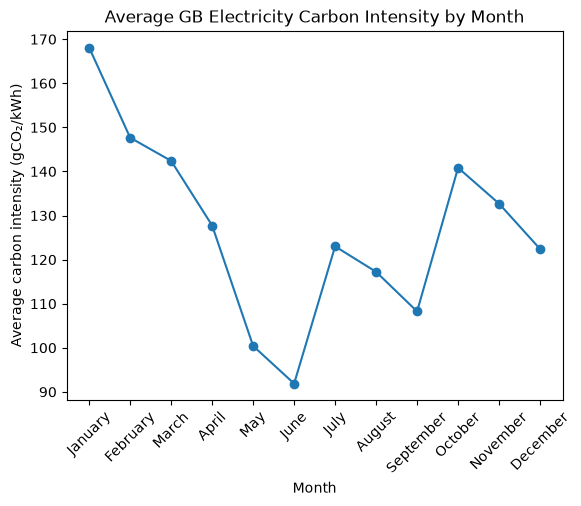

In [27]:
# Question 1c: How does carbon intensity vary by month?

# Aggregation
monthly_ci = (
    df_merged.groupby("MONTH_NAME")["CARBON_INTENSITY"]
      .mean()
)

# Defining month order for Python to not sort month names alphabetically!
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

monthly_ci = monthly_ci.reindex(month_order)

# Plotting

plt.plot(monthly_ci.index, monthly_ci.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Average carbon intensity (gCO₂/kWh)")
plt.title("Average GB Electricity Carbon Intensity by Month")

plt.xticks(rotation=45)

plt.show()

In [28]:
# Question 2: Does gas generation track carbon intensity?

# Find correlation coefficient
df_merged[["CARBON_INTENSITY", "GAS"]].corr()



,CARBON_INTENSITY,GAS
CARBON_INTENSITY,1.000000,0.926274
GAS,0.926274,1.000000


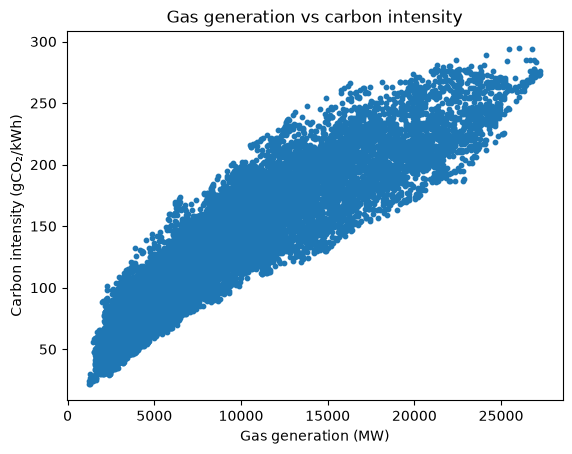

In [29]:
# Plot scatter diagram

plt.scatter(
    df_merged["GAS"],
    df_merged["CARBON_INTENSITY"],
    s=10
)

plt.xlabel("Gas generation (MW)")
plt.ylabel("Carbon intensity (gCO₂/kWh)")
plt.title("Gas generation vs carbon intensity")
plt.show()


In [30]:
# Question 3a: How does wind generation track carbon intensity?

# Find correlation coefficient
df_merged[["CARBON_INTENSITY", "WIND"]].corr()

,CARBON_INTENSITY,WIND
CARBON_INTENSITY,1.000000,-0.590543
WIND,-0.590543,1.000000


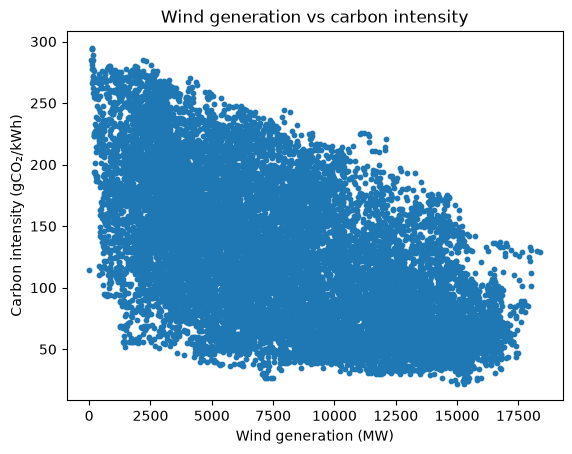

In [31]:
plt.scatter(
    df_merged["WIND"],
    df_merged["CARBON_INTENSITY"],
    s=10
)

plt.xlabel("Wind generation (MW)")
plt.ylabel("Carbon intensity (gCO₂/kWh)")
plt.title("Wind generation vs carbon intensity")
plt.show()


In [32]:
# Question 3b: How does solar generation track carbon intensity?

# Find correlation coefficient
df_merged[["CARBON_INTENSITY", "SOLAR"]].corr()

,CARBON_INTENSITY,SOLAR
CARBON_INTENSITY,1.000000,-0.306188
SOLAR,-0.306188,1.000000


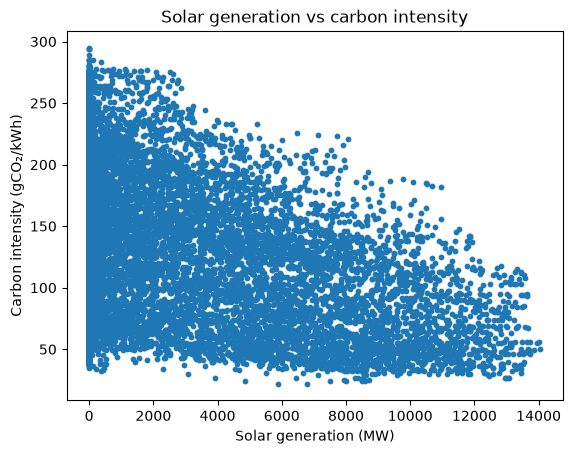

In [33]:
plt.scatter(
    df_merged["SOLAR"],
    df_merged["CARBON_INTENSITY"],
    s=10
)

plt.xlabel("Solar generation (MW)")
plt.ylabel("Carbon intensity (gCO₂/kWh)")
plt.title("Solar generation vs carbon intensity")
plt.show()

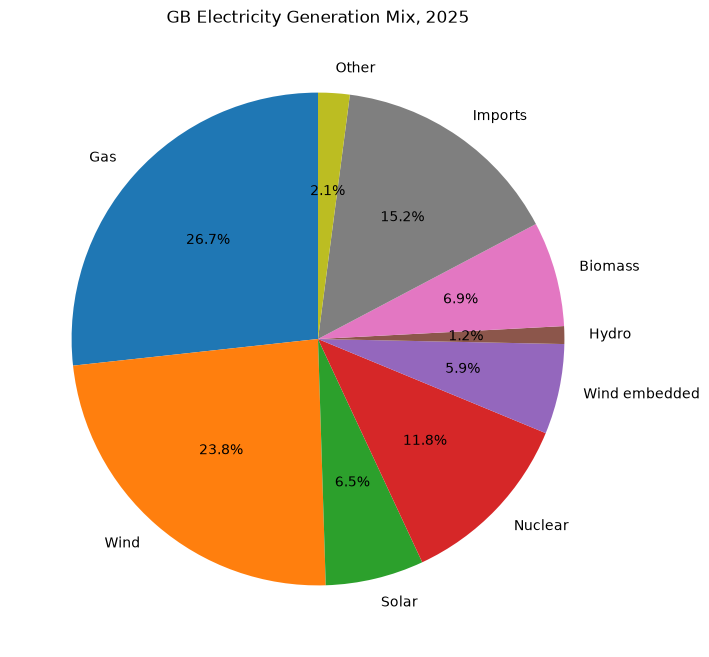

In [34]:
# Question 3c: How does the share of renewable generation affect carbon intensity?

# Visualise all forms of generation beyond the 'big four' of gas, wind, solar and nuclear
generation_totals = {
    "Gas": df_merged["GAS"].sum(),
    "Wind": df_merged["WIND"].sum(),
    "Solar": df_merged["SOLAR"].sum(),
    "Nuclear": df_merged["NUCLEAR"].sum(),
    "Wind embedded": df_merged["WIND_EMB"].sum(),
    "Hydro": df_merged["HYDRO"].sum(),
    "Biomass": df_merged["BIOMASS"].sum(),
    "Imports": df_merged["IMPORTS"].sum(),
}

generation_totals["Other"] = (
    df_merged["GENERATION"].sum()
    - sum(generation_totals.values())
)

# Plot the pie chart

plt.figure(figsize=(8, 8))

plt.pie(
    generation_totals.values(),
    labels=generation_totals.keys(),
    autopct="%1.1f%%",
    startangle=90
)

plt.title("GB Electricity Generation Mix, 2025")

plt.show()




In [35]:
big_four_sum = (
    df_merged["GAS"].sum()
    + df_merged["WIND"].sum()
    + df_merged["SOLAR"].sum()
    + df_merged["NUCLEAR"].sum()
)

four_share = 100 * big_four_sum / df_merged["GENERATION"].sum()

print(four_share)

68.76120760423444


Gas, wind, solar and nuclear accounted for 68.8% of total GB electricity generation in 2025. I therefore focus on these four sources when investigating the relationship between generation mix and carbon intensity, while recognising that other sources also contribute to the overall generation mix.

In [36]:
# Looking at the effect of two renewable generation sources, wind and solar, on carbon intensity

df_merged["RENEWABLES"] = (
    df_merged["WIND"]
    + df_merged["SOLAR"]
)

df_merged[["CARBON_INTENSITY", "RENEWABLES"]].corr()

,CARBON_INTENSITY,RENEWABLES
CARBON_INTENSITY,1.00000,-0.72093
RENEWABLES,-0.72093,1.00000


Wind and solar generation together have a stronger impact on carbon emissions than wind and solar generation by themselves. The correlation coefficient is -0.72 for renewables combined, compared with -0.59 for wind alone and -0.31 for solar alone.

In [37]:
# Question 4: Does higher electricity demand coincide with higher carbon intensity?

# Find correlation coefficient
df_merged[["CARBON_INTENSITY", "ND"]].corr()

,CARBON_INTENSITY,ND
CARBON_INTENSITY,1.000000,0.557584
ND,0.557584,1.000000


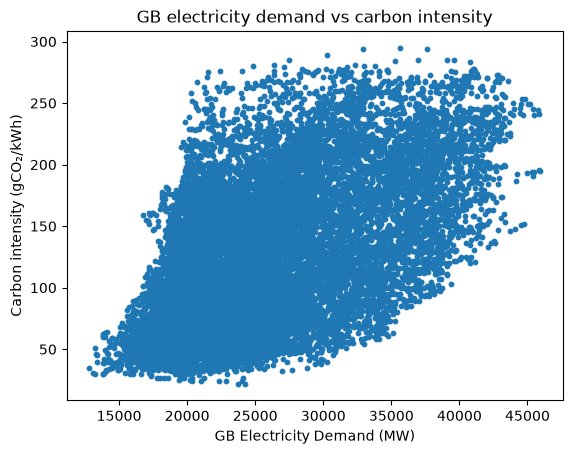

In [38]:
plt.scatter(
    df_merged["ND"],
    df_merged["CARBON_INTENSITY"],
    s=10
)

plt.xlabel("GB Electricity Demand (MW)")
plt.ylabel("Carbon intensity (gCO₂/kWh)")
plt.title("GB electricity demand vs carbon intensity")
plt.show()

There is weak positive correlation between national electricity demand and carbon intensity.

In [39]:
# Question 5: How does carbon intensity and generation mix vary on Wednesdays and Sundays?

daily_comparison = (
    df_merged[df_merged["DAY_OF_WEEK"].isin(["Wednesday", "Sunday"])]
    .groupby(["DAY_OF_WEEK", "HOUR"])[
        ["CARBON_INTENSITY", "GAS", "WIND", "SOLAR", "NUCLEAR"]
    ]
    .mean()
)

weds_gen = daily_comparison.loc["Wednesday"]

sunday_gen = daily_comparison.loc["Sunday"]



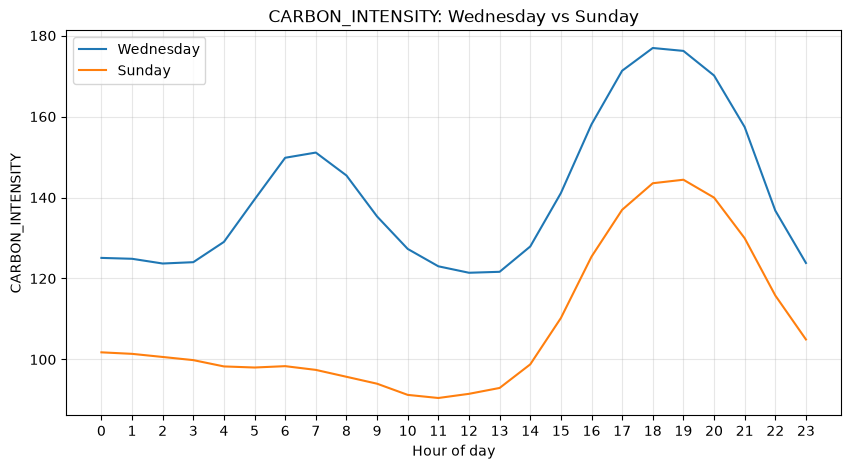

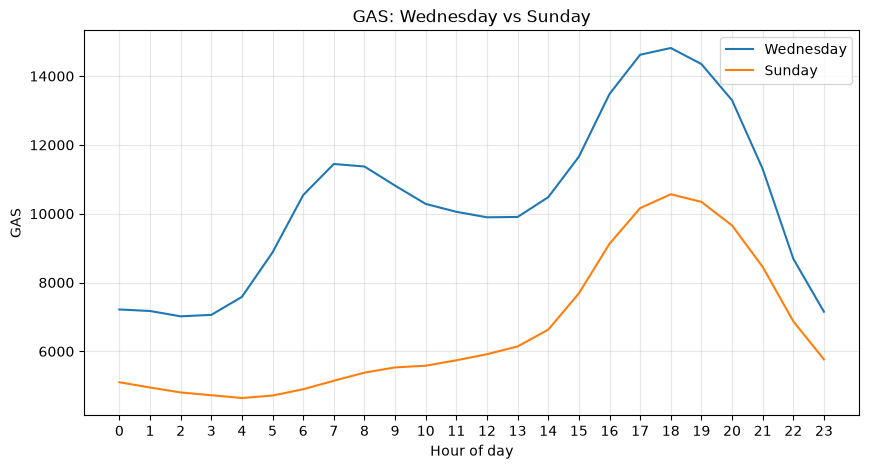

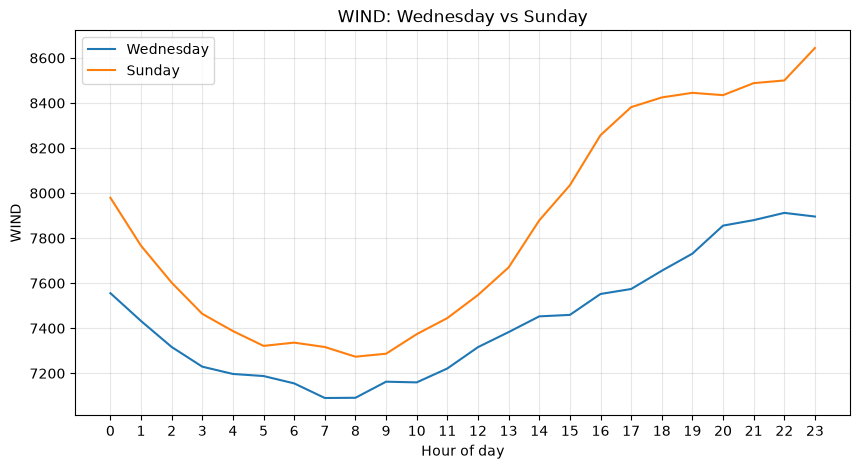

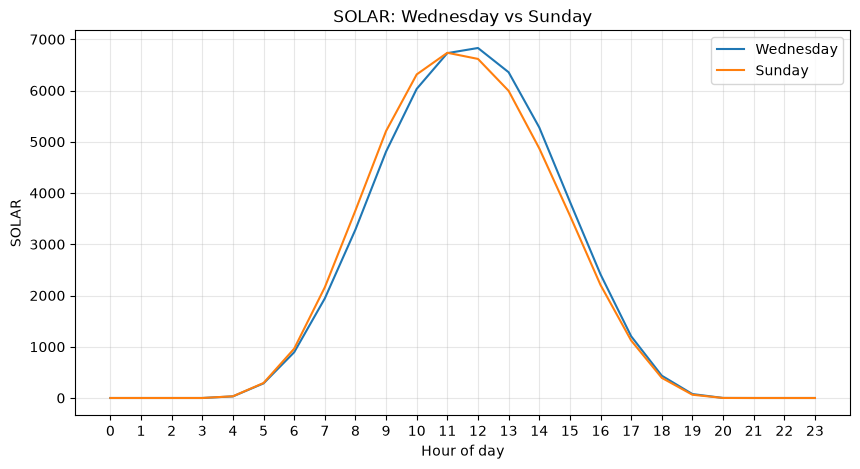

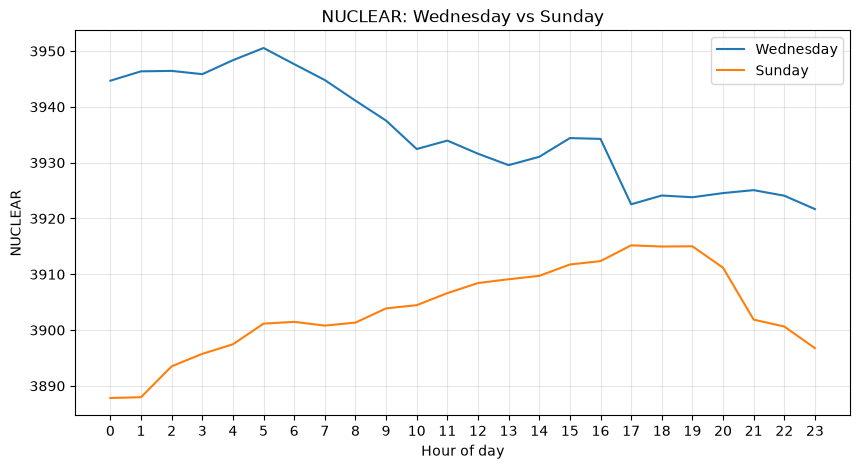

In [40]:
variables = [
    "CARBON_INTENSITY",
    "GAS",
    "WIND",
    "SOLAR",
    "NUCLEAR"
]

for variable in variables:

    plt.figure(figsize=(10, 5))

    plt.plot(
        weds_gen.index,
        weds_gen[variable],
        label="Wednesday"
    )

    plt.plot(
        sunday_gen.index,
        sunday_gen[variable],
        label="Sunday"
    )

    plt.xlabel("Hour of day")
    plt.ylabel(variable)
    plt.title(f"{variable}: Wednesday vs Sunday") 
    # can improve this code by adding lambda function to write correct units
    plt.xticks(range(24))
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

Wednesday has higher carbon intensity as already established. Here are some differences in the generation mix that may help explain that pattern. Gas generation is significantly higher on Wednesday than Sunday, whereas the reverse is true for wind. Solar generation is consistent across the two days. Nuclear generation, a low carbon source of baseload power, is higher on Wednesday as expected to satisfy the greater demand on that day.

In [44]:
# Question 6: What does the electricity system look like during high-carbon versus low-carbon periods?

threshold = df_merged["CARBON_INTENSITY"].median()

df_merged["carbon_group"] = np.where(
    df_merged["CARBON_INTENSITY"] >= threshold,
    "High carbon",
    "Low carbon"
)


sources = ["GAS", "WIND", "SOLAR", "NUCLEAR"]

# Calculate each source's share of total generation (%)
for source in sources:
    df_merged[f"{source}_PERC"] = (
        df_merged[source] / df_merged["GENERATION"] * 100
    )

# Average generation shares and national demand by carbon group
carbon_groups = df_merged.groupby("carbon_group").agg(
    {
        "GAS_PERC": "mean",
        "WIND_PERC": "mean",
        "SOLAR_PERC": "mean",
        "NUCLEAR_PERC": "mean",
        "ND": "mean"
    }
).round(1)

print(carbon_groups)


              GAS_PERC  WIND_PERC  SOLAR_PERC  NUCLEAR_PERC       ND
carbon_group                                                        
High carbon       37.9       16.1         3.8          11.6  28962.0
Low carbon        14.0       31.7         8.6          12.8  23313.5


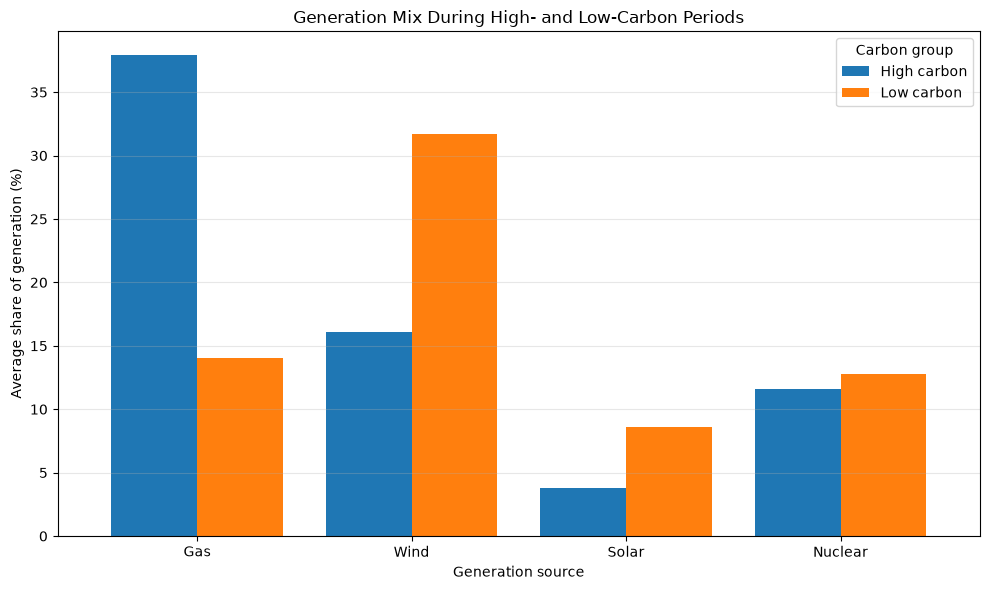

In [45]:
# Plotting a side-by-side bar chart using the generation percentages for the high and low carbon groups

plot_columns = [
    "GAS_PERC",
    "WIND_PERC",
    "SOLAR_PERC",
    "NUCLEAR_PERC"
]

plot_data = carbon_groups[plot_columns].copy()

# Make the labels easier to read
plot_data.columns = ["Gas", "Wind", "Solar", "Nuclear"]

ax = plot_data.T.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

ax.set_xlabel("Generation source")
ax.set_ylabel("Average share of generation (%)")
ax.set_title("Generation Mix During High- and Low-Carbon Periods")
ax.legend(title="Carbon group")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
# Calculating difference in demand between high- and low-carbon periods

low_demand = carbon_groups.loc["Low carbon", "ND"]
high_demand = carbon_groups.loc["High carbon", "ND"]

demand_difference = high_demand - low_demand

demand_percentage = (
    demand_difference / low_demand * 100
)

print(f"Average demand during low-carbon periods: {low_demand:,.0f} MW")
print(f"Average demand during high-carbon periods: {high_demand:,.0f} MW")
print(f"Difference in demand: {demand_difference:,.0f} MW")
print(
    f"Demand during high-carbon periods is "
    f"{demand_percentage:.1f}% higher than during low-carbon periods."
)

Average demand during low-carbon periods: 23,314 MW
Average demand during high-carbon periods: 28,962 MW
Difference in demand: 5,648 MW
Demand during high-carbon periods is 24.2% higher than during low-carbon periods.


Conclusions

Finding 1: Carbon intensity varies substantially throughout the time periods analysed. On an hourly level, the average carbon intensity peaks in the early morning (7am) and early evening (6pm) and troughs at midday.
Finding 2: Higher carbon-intensity periods tend to coincide with a higher proportion of gas generation.
Finding 3: Wind generation shows a moderate effect on reducing carbon intensity, but when combined with solar generation, has a much stronger effect overall on reducing carbon intensity.
Finding 4: Electricity demand alone does not appear to sufficiently account for carbon emission intensity. There is a weaker positive correlation than expected between the two variables. 
Finding 5: The Wednesday/Sunday comparison suggests a significant difference in generation mix and hence carbon intensity between the days. On Wednesday, the most carbon-intensive day of the week, more electricity is generated from gas and nuclear. However on Sunday, the least carbon-intensive day, wind plays a bigger role in power generation.